# NGC4567 and NGC4568: R-band and velocity segmentation

**2026-11-10 | MAUVE exploratory analysis**

[Shared workflow](https://chatgpt.com/s/t_6af33b62b26481919769d2055a7b3218).
Compare **A** (R-band light), **B** (R band and stellar velocity), and **C** (R band, stars and downweighted Hα).
Each valid Voronoi bin receives one galaxy label. Unmasked spaxels without a bin use the local photometric model.
The binary map describes projected membership. In the overlap, a single fitted velocity can mix light from both galaxies, and ionized gas can move differently from the stars. The map cannot recover the original component spectra.

## Inputs and footprint

Use the local MUSE-synthesized `R_FLUX` for the first run in place of the SDSS r image proposed in the shared thread. It is already on the MUSE grid. Use the SIMBAD crosswalk for nuclei, and the SDSS-derived inclinations and PAs in [Watts et al. (2023), Table 1](https://arxiv.org/abs/2303.07549) for the isophotal geometry. nGIST stellar KIN and gas BIN maps are used in their native relative velocity frame. The spatial mask defines the usable footprint. Only genuinely binned spaxels share kinematic evidence. Stellar S/N > 25 is kept as a separate quality mask.

In [1]:
%matplotlib inline

from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from scipy.optimize import least_squares
from scipy.special import expit, gammaincinv
from scipy.ndimage import label as connected_components

ROOT = Path.cwd()
CUBE = "NGC4567_8"
GALAXIES = ["NGC4567", "NGC4568"]

# Tunable region definitions
CONFIDENT_RADIUS_ARCSEC = {"NGC4567": 30.0, "NGC4568": 60.0}  # semi-major axes
MIXING_MIN_FRACTION = 0.20  # minimum modeled light share of either galaxy
MIXING_MAX_FRACTION = 1 - MIXING_MIN_FRACTION
if not 0 < MIXING_MIN_FRACTION < 0.5:
    raise ValueError("MIXING_MIN_FRACTION must be between 0 and 0.5.")

PRODUCT = ROOT / "v3tk_v7.6.8" / CUBE
SEED_CUTS = [0.60, 0.55, 0.65]  # axial fraction from the 4567 nucleus to the 4568 nucleus
CORE_EXCLUSION = 3.0  # arcsec
MIN_HA_SN = 3.0  # Hα uses a strict S/N > MIN_HA_SN cut
MAX_V_ERROR = {"Stars": 20.0}  # km/s

def read_maps(suffix, names):
    with fits.open(PRODUCT / f"{CUBE}_{suffix}.fits", memmap=True) as hdus:
        maps = {name: hdus[name].data.astype(float) for name in names}
        grids = {name: WCS(hdus[name].header).celestial for name in names}
    return maps, grids

kin, wk = read_maps("kin_maps", ["V", "FORM_ERR_V", "SNR_POSTFIT"])
gas, wg = read_maps("gas_bin_maps_further", [
    "BIN_ID", "V_STARS2", "HA6562_VEL", "HA6562_VEL_ERR", "HA6562_FLUX", "HA6562_FLUX_ERR"
])
spatial, ws = read_maps("spatial_binning_maps_further", ["BINID", "FLUX"])
wcs = wk["V"]
ny, nx = kin["V"].shape
grid_x, grid_y = [0, nx - 1, 0, nx - 1, nx / 2], [0, 0, ny - 1, ny - 1, ny / 2]
sky_check = wcs.pixel_to_world(grid_x, grid_y)
for grids, maps in [(wk, kin), (wg, gas), (ws, spatial)]:
    for name, grid in grids.items():
        assert maps[name].shape == (ny, nx), name
        assert np.max(sky_check.separation(grid.pixel_to_world(grid_x, grid_y)).arcsec) < 1e-4, name
np.testing.assert_array_equal(spatial["BINID"], gas["BIN_ID"])
np.testing.assert_array_equal(kin["V"], gas["V_STARS2"])

cube_row = pd.read_csv(ROOT / "cube_centers_v3tk.csv").set_index("ID").loc[CUBE]
assert (cube_row.ny, cube_row.nx) == (ny, nx)
catalog = pd.read_csv(ROOT / "simbad_object_crosswalk.csv").set_index("component").loc[GALAXIES]
centres = SkyCoord(catalog.ra_deg.to_numpy(), catalog.dec_deg.to_numpy(), unit="deg")
cx, cy = wcs.world_to_pixel(centres)
assert np.all((0 <= cx) & (cx < nx) & (0 <= cy) & (cy < ny))
inclination = pd.read_csv(ROOT / "MAUVE_Inclination.dat", sep=r"\s+", comment="#",
                         header=None, names=["galaxy", "inclination"]).set_index("galaxy").loc[GALAXIES, "inclination"]
colours = {}
for line in (ROOT / "MAUVE_galaxy_colors.dat").read_text().splitlines():
    fields = line.split()
    if len(fields) >= 4 and fields[1] in GALAXIES:
        colours[fields[1]] = fields[3]
assert set(colours) == set(GALAXIES)

footprint = np.isfinite(gas["BIN_ID"]) & (gas["BIN_ID"] >= 0)
py, px = np.nonzero(footprint)
ids, first, inverse, counts = np.unique(gas["BIN_ID"][footprint], return_index=True,
                                       return_inverse=True, return_counts=True)
assert np.all((ids >= 0) & (ids == np.floor(ids)))
bx = np.bincount(inverse, weights=px) / counts
by = np.bincount(inverse, weights=py) / counts
bin_icrs = wcs.pixel_to_world(bx, by).icrs
bin_sky = SkyCoord(ra=bin_icrs.ra, dec=bin_icrs.dec, frame="icrs")

def per_bin(image):
    values = image[footprint]
    np.testing.assert_array_equal(values, values[first][inverse])
    return values[first]

star = per_bin(kin["V"])
star_err = per_bin(kin["FORM_ERR_V"])
ha = per_bin(gas["HA6562_VEL"])
ha_err = per_bin(gas["HA6562_VEL_ERR"])
ha_flux = per_bin(gas["HA6562_FLUX"])
ha_flux_err = per_bin(gas["HA6562_FLUX_ERR"])
ha_sn = np.divide(ha_flux, ha_flux_err, out=np.full(len(ids), np.nan), where=ha_flux_err > 0)
tracers = {
    "Stars": (star, star_err, np.ones(len(ids), dtype=bool)),
    "Hα": (ha, ha_err, ha_sn > MIN_HA_SN),
}
offsets = []
for centre in centres:
    east, north = centre.spherical_offsets_to(bin_sky)
    offsets.append((east.arcsec, north.arcsec))
east12, north12 = centres[0].spherical_offsets_to(centres[1])
axis = np.array([east12.arcsec, north12.arcsec])
separation = np.linalg.norm(axis)
east, north = offsets[0]
fraction = (axis[0] * east + axis[1] * north) / separation**2
assert np.isfinite(fraction).all()
distance = np.array([np.hypot(e, n) for e, n in offsets])
print(f"{len(ids):,} distinct bins cover {footprint.sum():,} spaxels on a {nx} × {ny} grid.")
print(f"Cube centre CSV (x, y) = ({cube_row.center_x}, {cube_row.center_y}); nucleus separation = {separation:.1f} arcsec.")
display(catalog[["ra_deg", "dec_deg", "coordinate_bibcode"]].assign(x=cx, y=cy, inclination_deg=inclination))
postfit_snr = per_bin(kin["SNR_POSTFIT"])
snr25 = np.isfinite(postfit_snr) & (postfit_snr > 25)
with fits.open(PRODUCT / f"{CUBE}_mask.fits") as hdus:
    mask_column = hdus["MASKFILE"].data["MASK"]
    assert mask_column.size == ny * nx and np.isin(mask_column, [0, 1]).all()
    usable_pixels = mask_column.reshape(ny, nx) == 0
assert not np.any(footprint & ~usable_pixels)
unbinned = usable_pixels & ~footprint
print(f"Usable pixels: {usable_pixels.sum():,}; without a Voronoi bin: {unbinned.sum():,}.")

31,846 distinct bins cover 510,118 spaxels on a 971 × 1059 grid.
Cube centre CSV (x, y) = (486, 530); nucleus separation = 73.5 arcsec.


,ra_deg,dec_deg,coordinate_bibcode,x,y,inclination_deg
component,,,,,,
NGC4567,189.136242,11.257977,2020yCat.1350....0G,520.638848,782.511158,49
NGC4568,189.142883,11.238631,2006AJ....131.1163S,403.365187,434.286432,70


Usable pixels: 510,118; without a Voronoi bin: 0.


## 1. Put the two elliptical coordinate systems on the R-band image

The SIMBAD centres set the origins. The VERTICO inclinations and position angles set the flattened shape and orientation. For each galaxy, rotate the east and north offsets so that $x'_g$ is along the major axis (PA measured east of north) and $y'_g$ is along the minor axis. The projected axis ratio is $q_g^2=\cos^2 i_g+0.2^2\sin^2 i_g$. Every point on an ellipse has the same semi-major-axis radius $R_g=\sqrt{x_g'^2+(y_g'/q_g)^2}$.

The ellipses mark the same sample radii for each galaxy. Where they overlap, the same sky position has one elliptical radius relative to each centre. The dashed lines mark the projected major axes. Cell 6 uses each major axis and inner ellipse to define the confident region on its galaxy’s side.


In [2]:
PA_PHOT = np.array([251., 211.])
np.testing.assert_array_equal(inclination.to_numpy(), [49, 70])
q = np.hypot(np.cos(np.deg2rad(inclination.to_numpy())), 0.2 * np.sin(np.deg2rad(inclination.to_numpy())))
vri_path = ROOT.parent / "v3tk_to_VRI" / f"{CUBE}_DATACUBE_FINAL_WCS_Pall_mad_red_v3tk_VRI.fits"
with fits.open(vri_path) as hdus:
    r_flux = hdus["R_FLUX"].data.astype(float)
    r_wcs = WCS(hdus["R_FLUX"].header).celestial
assert r_flux.shape == usable_pixels.shape
assert np.max(sky_check.separation(r_wcs.pixel_to_world(grid_x, grid_y)).arcsec) < 1e-4

uy, ux = np.nonzero(usable_pixels)
sky = wcs.pixel_to_world(ux, uy).icrs
sky = SkyCoord(ra=sky.ra, dec=sky.dec, frame="icrs")
east_north = [centre.spherical_offsets_to(sky) for centre in centres]
coords = np.array([(east.arcsec, north.arcsec) for east, north in east_north])
t = (axis[0] * coords[0, 0] + axis[1] * coords[0, 1]) / separation**2
assert np.isfinite(t).all()
angle = np.deg2rad(PA_PHOT)[:, None]
east, north = coords[:, 0], coords[:, 1]
major = east * np.sin(angle) + north * np.cos(angle)
minor = east * np.cos(angle) - north * np.sin(angle)
radii = np.hypot(major, minor / q[:, None])
r_obs = r_flux[usable_pixels]
sample = (np.isfinite(r_obs) & (r_obs > 0) & (np.hypot(east, north).min(axis=0) > CORE_EXCLUSION)
          & (ux % 5 == 0) & (uy % 5 == 0))
holdout = ((ux // 30 + 2 * (uy // 30)) % 5) == 0


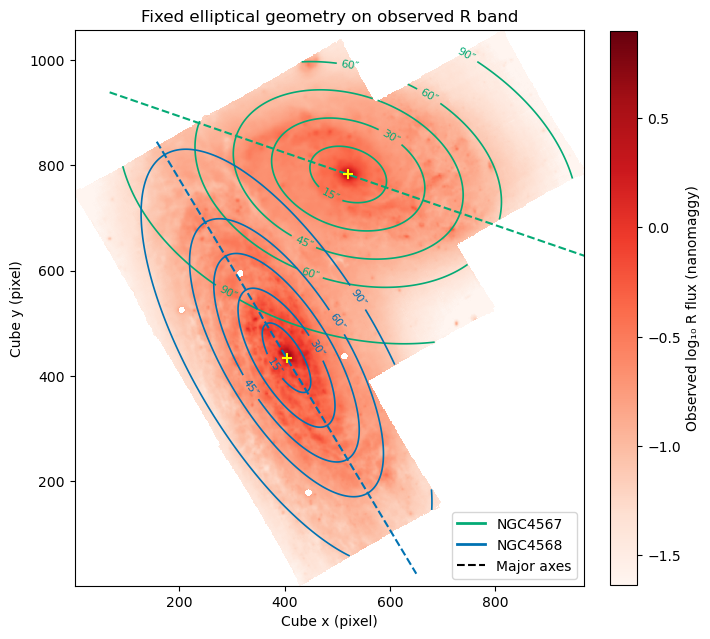

,Galaxy,Inclination (deg),PA (deg east of north),Projected axis ratio
0,NGC4567,49,251.0,0.673
1,NGC4568,70,211.0,0.390


In [3]:

from astropy import units as u

OUT = ROOT / "20261111_NGC4567_8_segmentation"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10})
label_cmap = ListedColormap([colours[g] for g in GALAXIES])
label_norm = BoundaryNorm([0.5, 1.5, 2.5], label_cmap.N)
def panel(ax, image, title, *, show_light_edge=False, **kwargs):
    im = ax.imshow(image, origin="lower", interpolation="nearest", rasterized=True, **kwargs)
    ax.set(title=title, xlim=(ux.min(), ux.max()), ylim=(uy.min(), uy.max()))
    if show_light_edge:
        ax.contour(light_edge, levels=[0], colors="white", linewidths=0.8, alpha=0.8)
    ax.scatter(cx, cy, marker="+", color="yellow", s=45, zorder=4)
    return im

def show_save(fig, name):
    for extension in ["png", "pdf"]:
        fig.savefig(OUT / f"{name}.{extension}", dpi=160)
    display(fig)
    plt.close(fig)


def on_sky(values):
    image = np.full((ny, nx), np.nan)
    image[usable_pixels] = values
    return image

observed_light = on_sky(np.log10(np.where(r_obs > 0, r_obs, np.nan)))
light_limits = dict(vmin=np.nanpercentile(observed_light, 2), vmax=np.nanmax(observed_light))
geometry_colours = {"NGC4567": "#04aa75", "NGC4568": "#0072B2"}
galaxy_handles = [Line2D([], [], color=geometry_colours[g], lw=2, label=g) for g in GALAXIES]

fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
im = panel(ax, observed_light, "Fixed elliptical geometry on observed R band", cmap="Reds", **light_limits)
for galaxy, centre, radius, major_offset, pa in zip(GALAXIES, centres, radii, major, PA_PHOT):
    colour = geometry_colours[galaxy]
    curves = ax.contour(on_sky(radius), levels=[15, 30, 45, 60, 90], colors=colour, linewidths=1.2)
    ax.clabel(curves, fmt='%d″', fontsize=8)
    extent = np.max(np.abs(major_offset))
    axis_offsets = np.linspace(-extent, extent, 101) * u.arcsec
    pa_rad = np.deg2rad(pa)
    axis_sky = centre.spherical_offsets_by(axis_offsets * np.sin(pa_rad), axis_offsets * np.cos(pa_rad))
    axis_x, axis_y = wcs.world_to_pixel(axis_sky)
    ax.plot(axis_x, axis_y, color=colour, ls="--", lw=1.5)
ax.legend(handles=galaxy_handles + [Line2D([], [], color="black", ls="--", label="Major axes")],
          loc="lower right")
ax.set(xlabel="Cube x (pixel)", ylabel="Cube y (pixel)")
fig.colorbar(im, ax=ax, shrink=.8, label="Observed log₁₀ R flux (nanomaggy)")
show_save(fig, "01_elliptical_geometry")
display(pd.DataFrame({"Galaxy": GALAXIES, "Inclination (deg)": inclination.to_numpy(),
                      "PA (deg east of north)": PA_PHOT, "Projected axis ratio": q}).round(3))


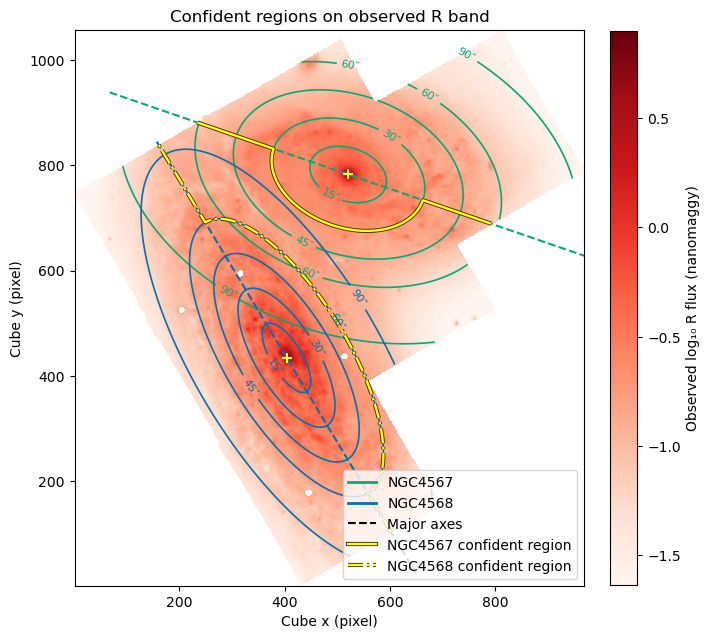

In [4]:
import matplotlib.patheffects as path_effects

companion_minor = []
for centre, companion, pa in zip(centres, centres[::-1], PA_PHOT):
    companion_east, companion_north = centre.spherical_offsets_to(companion)
    pa_rad = np.deg2rad(pa)
    companion_minor.append(companion_east.arcsec * np.cos(pa_rad) - companion_north.arcsec * np.sin(pa_rad))

# Positive inside the ellipse or on the side of the major axis away from the companion.
radius_limits = np.array([CONFIDENT_RADIUS_ARCSEC[galaxy] for galaxy in GALAXIES])[:, None]
outer_margin = -np.sign(companion_minor)[:, None] * minor
candidate_margin = np.maximum(radius_limits - radii, outer_margin)

# A pixel selected by both galaxies is ambiguous and stays unassigned.
confident_margin = np.minimum(candidate_margin, -candidate_margin[::-1])
confident_regions = {
    galaxy: on_sky(margin) > 0 for galaxy, margin in zip(GALAXIES, confident_margin)
}

fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
im = panel(ax, observed_light, "Confident regions on observed R band", cmap="Reds", **light_limits)
for galaxy, centre, radius, major_offset, pa in zip(GALAXIES, centres, radii, major, PA_PHOT):
    colour = geometry_colours[galaxy]
    curves = ax.contour(on_sky(radius), levels=[15, 30, 45, 60, 90], colors=colour, linewidths=1.2)
    ax.clabel(curves, fmt='%d″', fontsize=8)
    extent = np.max(np.abs(major_offset))
    axis_offsets = np.linspace(-extent, extent, 101) * u.arcsec
    pa_rad = np.deg2rad(pa)
    axis_sky = centre.spherical_offsets_by(axis_offsets * np.sin(pa_rad), axis_offsets * np.cos(pa_rad))
    axis_x, axis_y = wcs.world_to_pixel(axis_sky)
    ax.plot(axis_x, axis_y, color=colour, ls="--", lw=1.5)
boundary_styles = ["-", "-."]
boundary_effects = [path_effects.withStroke(linewidth=3.0, foreground="#3b3000")]
boundary_handles = []
for galaxy, margin, style in zip(GALAXIES, confident_margin, boundary_styles):
    boundary = ax.contour(
        on_sky(margin), levels=[0], colors="yellow", linestyles=style, linewidths=1.7, zorder=3,
    )
    boundary.set_path_effects(boundary_effects)
    boundary_handles.append(Line2D(
        [], [], color="yellow", ls=style, lw=1.7, path_effects=boundary_effects,
        label=f"{galaxy} confident region",
    ))

ax.legend(handles=galaxy_handles
          + [Line2D([], [], color="black", ls="--", label="Major axes")]
          + boundary_handles, loc="lower right")
ax.set(xlabel="Cube x (pixel)", ylabel="Cube y (pixel)")
fig.colorbar(im, ax=ax, shrink=.8, label="Observed log₁₀ R flux (nanomaggy)")
show_save(fig, "02_confident_regions")


## 2. Fit two Sérsic profiles using the confident regions

### Fixed input parameters

Each galaxy's geometry comes from cells 2 and 4 and is held fixed during the fit.

| Input | What it controls | NGC4567 | NGC4568 |
| --- | --- | --- | --- |
| Centre $(x_c,y_c)$ | The nucleus is the origin for that galaxy's radius. Its SIMBAD sky coordinates are projected onto the cube pixel grid. | SIMBAD NGC4567 centre | SIMBAD NGC4568 centre |
| Photometric position angle (PA) | The direction of the projected major axis, measured east of north. | 251° | 211° |
| Inclination $i$ and projected axis ratio $q$ | The inclination is the input tilt of the disc. The model uses $q$, the projected minor-to-major axis ratio computed from $i$ with intrinsic thickness 0.2. | $i=49^\circ$ | $i=70^\circ$ |
| Inner ellipse of the confident mask | The semi-major-axis radius used to select pixels in cell 6, set by `CONFIDENT_RADIUS_ARCSEC` in cell 2. | NGC4567 entry | NGC4568 entry |

For every cube pixel, project its offset from each nucleus onto that galaxy's major and minor axes. This gives two elliptical radii at the same pixel, one per galaxy, using $R_g=\sqrt{x_g'^2+(y_g'/q_g)^2}$.

### Input data used in the fit

The observed data are the **R-band flux per cube pixel** ($R_{\rm flux}$, in nanomaggies) and the two elliptical radii at that pixel. Select pixels from the **union of the two confident regions** in cell 6. Each region includes its inner ellipse and the half-plane on the far side of its major axis from the companion. A pixel in either region supplies one observed flux measurement. Both galaxies' predicted fluxes contribute to that measurement in the model.

Use usable pixels with finite, positive flux on the existing five-pixel sampling grid. Exclude pixels within 3″ of either nucleus. The unassigned interface stays outside the fitting sample. The flux values are used without a 0.18 nanomaggy threshold.

### Fitted parameters and their meaning

At elliptical radius $R_g$, each component has a Sérsic profile

$$
I_g(R_g)=I_{e,g}\exp\!\left[-b_{n_g}\left(\left(\frac{R_g}{R_{e,g}}\right)^{1/n_g}-1\right)\right].
$$

The fit returns three parameters per galaxy, six in total.

| Fitted parameter | What it means |
| --- | --- |
| $I_{e,g}$ (nanomaggies per cube pixel) | The predicted flux from galaxy $g$ alone at $R_g=R_{e,g}$. This sets the normalization of its profile. The optimizer fits $\ln I_{e,g}$ and the table reports $I_{e,g}$. |
| $R_{e,g}$ (arcsec) | The semi-major axis of the ellipse enclosing half the total light of that galaxy's Sérsic model. This sets its radial scale. |
| $n_g$ (dimensionless) | The Sérsic index, which controls how the profile changes slope with radius. $n=1$ gives an exponential profile. |

$b_n$ is calculated from $n$ by solving $P(2n,b_n)=1/2$ with the inverse regularized incomplete gamma function. [Graham & Driver (2005)](https://ned.ipac.caltech.edu/level5/March05/Graham/Graham2.html)

### Optimization and fit checks

Fit the six parameters jointly by minimizing $\ln[(I_{4567}+I_{4568})/R_{\rm flux}]$ with a soft-L1 loss of scale 0.25 in natural-log units. Each selected pixel enters with equal initial weight. Start at $\ln I_e=-2$ for both galaxies and $R_e=40″$ and $55″$ for NGC4567 and NGC4568, respectively. Try $(n_{4567},n_{4568})=(1,1),(2.5,1),(1,2.5)$ and retain the successful solution with the lowest cost. The bounds are $3\leq R_e\leq240$ arcsec, $0.5\leq n\leq6$, and $-12\leq\ln I_e\leq3$ in the input flux units.

Withhold one group of 30 × 30-pixel blocks and report the median signed residual, median absolute residual, and 90th percentile absolute residual in dex for the withheld pixels in each confident region. Then refit on all eligible pixels for the reported parameters and model maps. Predictions in the unassigned interface and excluded nuclei are extrapolations. The fit has no explicit PSF convolution or free sky term.

### Goodness of fit for the joint model

The primary goodness-of-fit table compares the sum of the two Sérsic predictions directly with the observed R-band flux, pooling both confident regions. It reports the final fit on every usable confident pixel with finite flux, the final fit on the sampled pixels used to optimize it, and the validation fit on the reserved spatial blocks. Flux RMSE and $R^2$ use every pixel in the corresponding row. The log residual statistics use pixels with positive observed flux.

### Goodness of fit for each component

A held-out sample is an eligible R-band pixel in a spatial block reserved for validation. Both Sérsic models are fitted using the other blocks before their predictions are evaluated on these pixels. The joint validation table compares the sum of the predictions with the observed flux, separately for each confident region.

For the component check, use the held-out pixels in galaxy $g$'s confident region. Subtract the companion's predicted flux from the observed R-band flux in linear units. Compare the resulting estimate for galaxy $g$ with its own predicted Sérsic flux. Report flux RMSE and $R^2$ on all of these pixels. Here $R^2=1-\sum (I_g-F_g)^2/\sum(F_g-\overline{F_g})^2$, where $F_g$ is the companion-subtracted flux. It compares the model with a constant equal to the mean of that flux. The median and 90th percentile absolute log residual use only pixels whose companion-subtracted flux is positive. The table gives both sample counts.

The component metrics depend on the companion model used in the subtraction. In linear units the residual is algebraically the same as the summed-model residual at those pixels. The component log residual shows how large the error is relative to the estimated light from that galaxy.

The full-area table evaluates the **final** two-component fit on every usable pixel with finite R-band flux inside either confident mask. This includes the central 3″ and pixels between the sampling points used in the fit. The component comparison uses the same companion subtraction and metrics as the held-out table. Full-area residuals show agreement across the confident footprint, including the extrapolation into the excluded cores. The held-out table checks spatial prediction on blocks that were omitted from the validation fit.


In [5]:
def sersic_log_components(params, radius):
    log_ie, re, index = params.reshape(2, 3).T[:, :, None]
    bn = gammaincinv(2 * index, 0.5)
    return log_ie - bn * ((radius / re)**(1 / index) - 1)


def fit_sersic_light(use):
    radius = radii[:, use]
    log_observed = np.log(r_obs[use])

    def residual(params):
        return np.logaddexp(*sersic_log_components(params, radius)) - log_observed

    trials = [
        least_squares(
            residual, [-2., 40., n1, -2., 55., n2],
            bounds=([-12., 3., 0.5] * 2, [3., 240., 6.] * 2),
            loss="soft_l1", f_scale=0.25, x_scale="jac",
        )
        for n1, n2 in [(1., 1.), (2.5, 1.), (1., 2.5)]
    ]
    return min((trial for trial in trials if trial.success), key=lambda trial: trial.cost)


confident_pixels = np.array([confident_regions[g][usable_pixels] for g in GALAXIES])
sersic_samples = sample & confident_pixels.any(axis=0)
validation_samples = sersic_samples & holdout
training_samples = sersic_samples & ~holdout
validation_fit = fit_sersic_light(training_samples)
validation_log_components = sersic_log_components(validation_fit.x, radii[:, validation_samples])
validation_observed = r_obs[validation_samples]
validation_residual = (
    np.logaddexp(*validation_log_components) - np.log(validation_observed)
) / np.log(10)

sersic_fit = fit_sersic_light(sersic_samples)
log_ie, re, index = sersic_fit.x.reshape(2, 3).T
bound_names = ("ln Ie", "Re", "n")
sersic_parameters = pd.DataFrame({
    "Galaxy": GALAXIES,
    "Ie (nanomaggy per pixel)": np.exp(log_ie),
    "Re (arcsec)": re,
    "n": index,
    "Parameters at bounds": [
        ", ".join(name for name, flag in zip(bound_names, flags) if flag) or "None"
        for flags in sersic_fit.active_mask.reshape(2, 3)
    ],
})
sersic_checks = []
for galaxy, region in zip(GALAXIES, confident_pixels):
    residual = validation_residual[region[validation_samples]]
    sersic_checks.append({
        "Region": galaxy,
        "Final fit samples": int((sersic_samples & region).sum()),
        "Held-out samples": residual.size,
        "Median residual (dex)": np.median(residual),
        "Median |residual| (dex)": np.median(np.abs(residual)),
        "P90 |residual| (dex)": np.percentile(np.abs(residual), 90),
    })
sersic_validation = pd.DataFrame(sersic_checks)
display(sersic_parameters.round(4))
display(sersic_validation.round(3))

def sersic_flux_metrics(model, target):
    flux_residual = model - target
    total_variance = np.sum((target - target.mean())**2)
    positive = target > 0
    abs_log_residual = np.abs(np.log10(model[positive] / target[positive]))
    return {
        "Flux RMSE (nanomaggy per pixel)": np.sqrt(np.mean(flux_residual**2)),
        "Flux R²": 1 - np.sum(flux_residual**2) / total_variance if total_variance > 0 else np.nan,
        "Median |residual| (dex)": np.median(abs_log_residual) if positive.any() else np.nan,
        "P90 |residual| (dex)": np.percentile(abs_log_residual, 90) if positive.any() else np.nan,
    }


def check_sersic_components(params, use, pixel_column):
    components = np.exp(sersic_log_components(params, radii[:, use]))
    observed = r_obs[use]
    component_checks = []
    for galaxy, region, predicted, companion in zip(
        GALAXIES, confident_pixels, components, components[::-1],
    ):
        in_region = region[use]
        target = observed[in_region] - companion[in_region]
        model = predicted[in_region]
        component_checks.append({
            "Galaxy": galaxy,
            pixel_column: target.size,
            "Positive after subtraction": np.count_nonzero(target > 0),
            **sersic_flux_metrics(model, target),
        })
    return pd.DataFrame(component_checks)


all_confident_samples = confident_pixels.any(axis=0) & np.isfinite(r_obs)
joint_checks = []
for evaluation, params, use in [
    ("Final fit · all confident pixels", sersic_fit.x, all_confident_samples),
    ("Final fit · fitted samples", sersic_fit.x, sersic_samples),
    ("Validation fit · held-out blocks", validation_fit.x, validation_samples),
]:
    target = r_obs[use]
    model = np.exp(np.logaddexp(*sersic_log_components(params, radii[:, use])))
    joint_checks.append({
        "Joint model evaluation": evaluation,
        "Pixels": target.size,
        "Positive observed flux": np.count_nonzero(target > 0),
        **sersic_flux_metrics(model, target),
    })
sersic_joint_fit_quality = pd.DataFrame(joint_checks)
display(sersic_joint_fit_quality.round(3))

sersic_component_full = check_sersic_components(sersic_fit.x, all_confident_samples, "Confident pixels")
sersic_component_validation = check_sersic_components(validation_fit.x, validation_samples, "Held-out pixels")
display(sersic_component_full.round(3))
display(sersic_component_validation.round(3))


,Galaxy,Ie (nanomaggy per pixel),Re (arcsec),n,Parameters at bounds
0,NGC4567,0.1032,49.1698,0.9007,None
1,NGC4568,0.1613,52.8961,1.1304,None


,Region,Final fit samples,Held-out samples,Median residual (dex),Median |residual| (dex),P90 |residual| (dex)
0,NGC4567,6478,1263,-0.005,0.060,0.145
1,NGC4568,8759,1765,0.008,0.068,0.146


,Joint model evaluation,Pixels,Positive observed flux,Flux RMSE (nanomaggy per pixel),Flux R²,Median |residual| (dex),P90 |residual| (dex)
0,Final fit · all confident pixels,382340,382340,0.125,0.641,0.065,0.151
1,Final fit · fitted samples,15237,15237,0.064,0.840,0.065,0.150
2,Validation fit · held-out blocks,3028,3028,0.051,0.887,0.065,0.145


,Galaxy,Confident pixels,Positive after subtraction,Flux RMSE (nanomaggy per pixel),Flux R²,Median |residual| (dex),P90 |residual| (dex)
0,NGC4567,162651,162651,0.128,0.471,0.058,0.150
1,NGC4568,219689,219686,0.122,0.704,0.082,0.187


,Galaxy,Held-out pixels,Positive after subtraction,Flux RMSE (nanomaggy per pixel),Flux R²,Median |residual| (dex),P90 |residual| (dex)
0,NGC4567,1263,1263,0.040,0.868,0.062,0.156
1,NGC4568,1765,1765,0.057,0.885,0.076,0.178


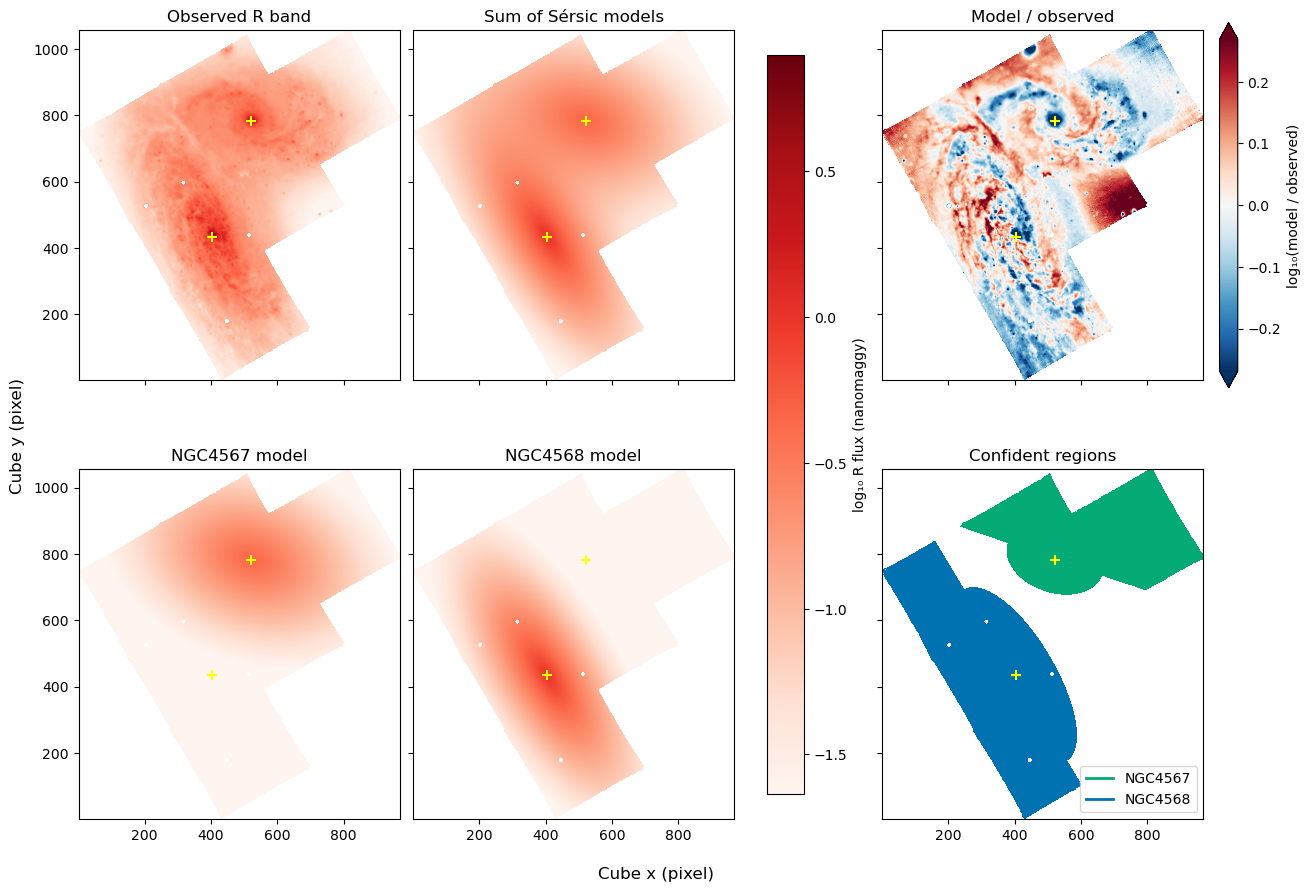

In [6]:
log_components = sersic_log_components(sersic_fit.x, radii)
light_model = np.exp(log_components)
log_total = np.logaddexp(*log_components) / np.log(10)
model_residual = on_sky(log_total) - observed_light
region_image = on_sky(np.where(confident_pixels[0], 1., np.where(confident_pixels[1], 2., np.nan)))

fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex=True, sharey=True)
light_panels = [
    (axes[0, 0], observed_light, "Observed R band"),
    (axes[0, 1], on_sky(log_total), "Sum of Sérsic models"),
    (axes[1, 0], on_sky(log_components[0] / np.log(10)), "NGC4567 model"),
    (axes[1, 1], on_sky(log_components[1] / np.log(10)), "NGC4568 model"),
]
for ax, data, title in light_panels:
    im = panel(ax, data, title, cmap="Reds", **light_limits)
fig.colorbar(im, ax=axes[:, :2], shrink=.85, label="log₁₀ R flux (nanomaggy)")

residual_limit = np.nanpercentile(np.abs(model_residual), 98)
im = panel(axes[0, 2], model_residual, "Model / observed", cmap="RdBu_r",
           vmin=-residual_limit, vmax=residual_limit)
fig.colorbar(im, ax=axes[0, 2], shrink=.85, extend="both",
             label="log₁₀(model / observed)")
region_cmap = ListedColormap([geometry_colours[g] for g in GALAXIES])
panel(axes[1, 2], region_image, "Confident regions", cmap=region_cmap, norm=label_norm)
axes[1, 2].legend(handles=galaxy_handles, loc="lower right")
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "03_sersic_confident_regions")


## 3. First boundary from equal modeled R-band light

Use the two Sérsic components from the final fit in cell 8, with the 3″ exclusion around each nucleus. At every usable cube pixel, compare the individual predicted fluxes at that sky position using the log light ratio

$$
D_R = \log_{10}\!\left(\frac{I_{4567}}{I_{4568}}\right).
$$

The first boundary is the $D_R=0$ contour, where each galaxy contributes half of the total modeled R-band light. On the $D_R>0$ side the NGC4567 model is brighter. On the $D_R<0$ side the NGC4568 model is brighter. The contour is interpolated between cube pixels. It uses only the photometric model and extends into the interface using predictions from the fits to the confident regions.

### Mixing region after protecting the confident regions

The confident masks from cell 6 take precedence. Each combines the inner ellipse with semi-major axis set by `CONFIDENT_RADIUS_ARCSEC` in cell 2 with the half-plane across the galaxy's major axis from the companion. Pixels in a confident mask belong to that galaxy. Elsewhere, a pixel is in the mixing region if its modeled NGC4567 share $f_{4567}=I_{4567}/(I_{4567}+I_{4568})$ lies between the configured lower fraction and its complement, inclusive. The defaults are 32% and 68%. Set the lower edge with `MIXING_MIN_FRACTION` in cell 2.

The solid yellow line is the 50% light reference. The dotted yellow outline encloses the resulting mixing region. Its edge follows a light-fraction threshold or a confident-mask boundary, whichever restricts the mixing region at that location.

The velocity analysis uses Voronoi bins. A bin touching either confident region is excluded from mixing so that no confident spaxel can be reassigned. For the remaining bins, apply the same configured mixing limits to the fraction calculated from the summed Sérsic component fluxes. The resulting bin-level boundary can differ from the pixel-level outline shown here.


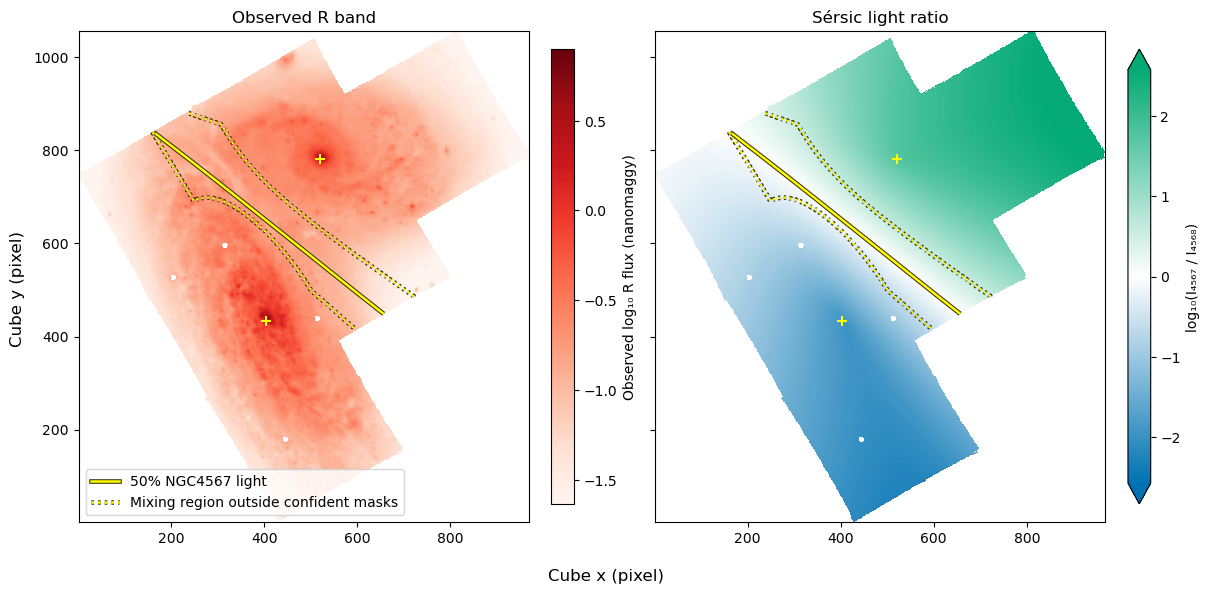

In [7]:
from matplotlib.colors import LinearSegmentedColormap

sersic_log_ratio = on_sky((log_components[0] - log_components[1]) / np.log(10))
mixing_limits = np.array([MIXING_MIN_FRACTION, MIXING_MAX_FRACTION])
mixing_log_ratio = np.log10(mixing_limits / (1 - mixing_limits))
confident_footprint = np.logical_or.reduce([confident_regions[g] for g in GALAXIES])
light_mixing_region = (
    (sersic_log_ratio >= mixing_log_ratio[0]) & (sersic_log_ratio <= mixing_log_ratio[1])
    & ~confident_footprint
)
ratio_cmap = LinearSegmentedColormap.from_list(
    "galaxy_light_ratio", [geometry_colours["NGC4568"], "white", geometry_colours["NGC4567"]],
)
ratio_limit = np.nanpercentile(np.abs(sersic_log_ratio), 98)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained", sharex=True, sharey=True)
im = panel(axes[0], observed_light, "Observed R band", cmap="Reds", **light_limits)
fig.colorbar(im, ax=axes[0], shrink=.8, label="Observed log₁₀ R flux (nanomaggy)")
im = panel(axes[1], sersic_log_ratio, "Sérsic light ratio", cmap=ratio_cmap,
           vmin=-ratio_limit, vmax=ratio_limit)
fig.colorbar(im, ax=axes[1], shrink=.8, extend="both",
             label="log₁₀(I₄₅₆₇ / I₄₅₆₈)")

equal_light_style = dict(color="yellow", lw=1.8,
                         path_effects=[path_effects.withStroke(linewidth=3.3, foreground="#383000")])
def draw_light_boundaries(ax, mixing_region):
    equal = ax.contour(sersic_log_ratio, levels=[0], colors=equal_light_style["color"],
                       linewidths=equal_light_style["lw"], zorder=3)
    mixing_outline = ax.contour(
        np.where(usable_pixels, mixing_region, np.nan), levels=[0.5],
        colors=equal_light_style["color"], linestyles=":", linewidths=1.6, zorder=3,
    )
    for contour in (equal, mixing_outline):
        contour.set_path_effects(equal_light_style["path_effects"])


for ax in axes:
    draw_light_boundaries(ax, light_mixing_region)
axes[0].legend(handles=[
    Line2D([], [], label="50% NGC4567 light", **equal_light_style),
    Line2D([], [], ls=":", label="Mixing region outside confident masks", **equal_light_style),
], loc="lower left")
fig.supxlabel("Cube x (pixel)")
fig.supylabel("Cube y (pixel)")
show_save(fig, "04_sersic_equal_light_boundary")


In [8]:
# Export the pixel-level photometric segmentation defined in cell 11.
photometric_labels = np.full(usable_pixels.shape, np.nan, dtype=np.float32)
photometric_labels[usable_pixels] = np.where(sersic_log_ratio[usable_pixels] >= 0, 1, 2)
photometric_labels[light_mixing_region] = 0
for galaxy_id, galaxy in enumerate(GALAXIES, start=1):
    photometric_labels[confident_regions[galaxy]] = galaxy_id

segmentation_header = wcs.to_header()
segmentation_header["SEGTYPE"] = ("PHOTOMETRIC", "R-band Sersic segmentation")
segmentation_header["MASKVAL"] = ("NaN", "Outside the usable footprint")
segmentation_header["LABEL0"] = (0, "Mixing region")
segmentation_header["LABEL1"] = (1, "NGC4567")
segmentation_header["LABEL2"] = (2, "NGC4568")
segmentation_header["MIXLO"] = (float(mixing_limits[0]), "Lower modeled NGC4567 light fraction")
segmentation_header["MIXHI"] = (float(mixing_limits[1]), "Upper modeled NGC4567 light fraction")
segmentation_header["RAD4567"] = (CONFIDENT_RADIUS_ARCSEC["NGC4567"], "Confident ellipse semi-major axis (arcsec)")
segmentation_header["RAD4568"] = (CONFIDENT_RADIUS_ARCSEC["NGC4568"], "Confident ellipse semi-major axis (arcsec)")

photometric_fits_path = ROOT / "NGC4567_8_photometric_segmentation.fits"
fits.PrimaryHDU(data=photometric_labels, header=segmentation_header).writeto(
    photometric_fits_path, overwrite=True, checksum=True,
)
print(f"Saved {photometric_fits_path}")
print(f"NaN Outside footprint  {np.count_nonzero(np.isnan(photometric_labels)):,} pixels")
for label, name in [(0, "Mixing"), (1, "NGC4567"), (2, "NGC4568")]:
    print(f"{label:2d}  {name:<18} {np.count_nonzero(photometric_labels == label):,} pixels")


Saved /Users/Igniz/Desktop/ICRAR/further/NGC4567_8_photometric_segmentation.fits
NaN Outside footprint  518,171 pixels
 0  Mixing             67,210 pixels
 1  NGC4567            205,412 pixels
 2  NGC4568            237,496 pixels


## 4. Fit the stellar velocity field of each galaxy

### Inputs and training bins

Use the nGIST stellar line-of-sight velocity $v_{\star}$ (KIN map `V`) and its formal error $\epsilon_{\star}$ (`FORM_ERR_V`), in km/s on the native nGIST velocity zero point. Each Voronoi bin supplies one measurement and its position is the mean of its cube pixel coordinates. Sum each Sérsic component over the bin's spaxels and calculate the NGC4567 light fraction $f_{4567}=F_{4567}/(F_{4567}+F_{4568})$. A bin touching a single confident region is assigned to that galaxy for training. For bins touching neither, fractions above the upper mixing limit select NGC4567, and fractions below the lower limit select NGC4568. Bins inside the configured limits that touch neither mask are reserved for refinement. A bin touching both confident masks supplies neither fit nor refinement. Training requires finite velocity, $0<\epsilon_\star\leq20$ km/s, and a bin centre more than 3″ from either nucleus. Each selected bin has equal initial weight. The inputs include the fixed SIMBAD centres and inclinations ($49^\circ$ and $70^\circ$).

$\epsilon_\star$ (epsilon-star) is the **formal measurement uncertainty on the fitted mean stellar velocity of one bin**, in km/s. Every spaxel in that Voronoi bin shares the same measurement and error. The two galaxy models are compared to the same observed velocity and error. The stellar velocity dispersion describes the width of the underlying stellar velocity distribution and is a different quantity.

### Model and fitted parameters

The rotation curve gives the rotation amplitude as a function of distance from the nucleus. The disk geometry projects that curve along the line of sight to give a **two-dimensional velocity field**. At an interface bin, the NGC4567 model asks what velocity would be expected if that bin were dominated by NGC4567. The NGC4568 model makes a second prediction for the same bin.

For a trial kinematic PA, rotate the east and north offsets into coordinates $x'$ along the receding major axis and $y'$ along the minor axis. For this thin rotating-disk model the disk-plane radius is $R_{\rm disk}=\sqrt{x'^2+(y'/\cos i)^2}$. The Sérsic light model continues to use the projected photometric axis ratio from cell 4. **Deproject the position and project the model velocity.** The optimizer takes the measured line-of-sight velocity as its target. It never divides the measurement by $\sin i$ or $\cos\theta$. The intrinsic model rotation speed is $V_{\rm rot}(R)=V_\infty R/\sqrt{R^2+R_t^2}$. Its line-of-sight contribution is $V_{\rm rot}(R)\sin i\cos\theta$, where $\cos\theta=x'/R$ in the disk plane. Since $i$ is fixed, the code fits the projected amplitude $A=V_\infty\sin i$ directly. The predicted line-of-sight velocity is

$$
v_{\star,g}=v_{0,g}+A_g\frac{x'}{\sqrt{R_{\rm disk}^2+R_{t,g}^2}}.
$$

| Fitted parameter | Meaning |
| --- | --- |
| $v_{0,g}$ (km/s) | Velocity of the galaxy centre in the nGIST frame. |
| $A_g$ (km/s) | Asymptotic projected rotation amplitude along the major axis. The implied in-plane amplitude is $V_{\infty,g}=A_g/\sin i_g$. |
| Kinematic PA (deg east of north) | Direction of the receding major axis, fitted independently of the photometric PA. |
| $R_{t,g}$ (arcsec) | Turnover scale of the rotation curve. |

Use a soft-L1 loss with a scale of 10 km/s and four starting PAs separated by 90°. Fit each disk using all of its eligible unmixed bins. Let $\mathcal T_g$ denote those bins and $N_g$ their number. The velocity score uses the RMS residual of the final fit in that region,

$$
s_g = \sqrt{\frac{1}{N_g}\sum_{j\in\mathcal T_g}
  (v_{\star,j}-v_{{\rm pred},g,j})^2}.
$$

This is an in-sample residual scale in km/s. Evaluate each disk at every bin centre, including the mixing region. The 99.5th percentile of the fitted training radii flags predictions beyond radial support in the assignment summary.


In [9]:
def stellar_disk_coordinates(offset, inc, pa):
    east, north = offset
    major_offset = east * np.sin(pa) + north * np.cos(pa)
    minor_offset = east * np.cos(pa) - north * np.sin(pa)
    disk_minor = minor_offset / np.cos(np.deg2rad(inc))
    return major_offset, disk_minor, np.hypot(major_offset, disk_minor)


def stellar_disk(params, offset, inc):
    v0, amplitude, pa, turnover = params
    major_offset, _, radius = stellar_disk_coordinates(offset, inc, pa)
    return v0 + amplitude * major_offset / np.hypot(radius, turnover), radius


def fit_velocity_disk(offset, velocity, inc, use):
    local_offset = tuple(coord[use] for coord in offset)
    target = velocity[use]

    def residual(params):
        return stellar_disk(params, local_offset, inc)[0] - target

    trials = [
        least_squares(
            residual, [np.median(target), 130., pa, 20.],
            bounds=([-300., 0., -4*np.pi, 1.], [300., 400., 4*np.pi, 150.]),
            loss="soft_l1", f_scale=10., x_scale=[50., 100., 1., 30.],
        )
        for pa in np.linspace(0, 2*np.pi, 4, endpoint=False)
    ]
    return min((fit for fit in trials if fit.success), key=lambda fit: fit.cost)


stellar_qc = np.isfinite(star) & np.isfinite(star_err) & (star_err > 0) & (star_err <= MAX_V_ERROR["Stars"])
component_bin_flux = np.array([
    np.bincount(inverse, weights=component[footprint[usable_pixels]], minlength=len(ids))
    for component in light_model
])
light_bin_fraction = component_bin_flux[0] / component_bin_flux.sum(axis=0)
bin_touches_confident = np.array([
    np.bincount(inverse, weights=confident_regions[g][footprint], minlength=len(ids)) > 0
    for g in GALAXIES
])
no_confident_pixels = ~bin_touches_confident.any(axis=0)
confident_bin_lock = bin_touches_confident & ~bin_touches_confident[::-1]
fraction_in_band = (light_bin_fraction >= mixing_limits[0]) & (light_bin_fraction <= mixing_limits[1])
bin_mixing = no_confident_pixels & fraction_in_band
stellar_training_side = confident_bin_lock | (no_confident_pixels & np.array([
    light_bin_fraction > mixing_limits[1],
    light_bin_fraction < mixing_limits[0],
]))
outside_cores = distance.min(axis=0) > CORE_EXCLUSION


def fit_disk_models(velocity, quality):
    models = {}
    parameters = {}
    rows = []
    fit_bins = stellar_training_side & quality & outside_cores
    for galaxy, inc, offset, seed in zip(GALAXIES, inclination, offsets, fit_bins):
        fit = fit_velocity_disk(offset, velocity, inc, seed)
        parameters[galaxy] = fit.x
        prediction, radius = stellar_disk(fit.x, offset, inc)
        fit_residual = velocity[seed] - prediction[seed]
        scatter = np.sqrt(np.mean(fit_residual**2))
        max_radius = np.percentile(radius[seed], 99.5)
        models[galaxy] = (prediction, scatter, radius <= max_radius)
        v0, amplitude, pa, turnover = fit.x
        rows.append({
            "Galaxy": galaxy, "Fit bins": seed.sum(),
            "v0 (km/s)": v0, "A (km/s)": amplitude, "Kinematic PA (deg)": np.rad2deg(pa) % 360,
            "V_inf (km/s)": amplitude / np.sin(np.deg2rad(inc)),
            "Rt (arcsec)": turnover, "Fit RMS residual (km/s)": scatter,
            "Fit P90 absolute residual (km/s)": np.percentile(np.abs(fit_residual), 90),
            "Support radius (arcsec)": max_radius,
            "Parameters at bounds": np.count_nonzero(fit.active_mask),
        })
    return models, parameters, fit_bins, pd.DataFrame(rows)


stellar_models, stellar_fit_parameters, stellar_fit_bins, stellar_fit_summary = fit_disk_models(star, stellar_qc)
display(stellar_fit_summary.round(2))


,Galaxy,Fit bins,v0 (km/s),A (km/s),Kinematic PA (deg),V_inf (km/s),Rt (arcsec),Fit RMS residual (km/s),Fit P90 absolute residual (km/s),Support radius (arcsec),Parameters at bounds
0,NGC4567,9692,46.61,95.17,91.00,126.10,19.29,6.55,10.77,74.92,0
1,NGC4568,18077,16.32,138.85,27.56,147.77,10.11,7.41,12.07,109.31,0


### Inspect the stellar models in the disk plane and on the sky

**Face-on maps.** For each galaxy, rotate its training-bin positions by the fitted kinematic PA, then use the disk-plane coordinates $(x',y'/\cos i)$. Plot one marker per Voronoi-bin centre, with marker area scaled by bin size. The first panel in each row infers the signed circular speed from the measured velocity under that galaxy's disk geometry:

$$
V_{\rm inferred}=\frac{v_\star-v_0}{\sin i\,\cos\theta},
\qquad \cos\theta=\frac{x'}{R_{\rm disk}}.
$$

This inversion is for display. Cell 14 fits the velocities in the observed line-of-sight frame. Use $|\cos\theta|\geq0.35$ in the face-on maps because dividing by $\cos\theta$ amplifies errors near the minor axis. The second panel evaluates $V_{\rm rot}(R_{\rm disk})$ at the same bins and the third shows $V_{\rm inferred}-V_{\rm rot}$. Positive residuals mean the inferred rotation speed exceeds the model. The face-on maps show the training bins that pass the display cut.

**Projected maps.** In cube coordinates, evaluate each disk model in every Voronoi bin on its assigned non-mixing side and in every mixing bin outside the confident regions. Both disks therefore provide predictions for the same full mixing band. The maps include predictions beyond each model's radial support and bins excluded from fitting. The adjacent residual map subtracts the prediction from the measured stellar velocity wherever that velocity is finite. The table reports full mixing-band coverage, counts predictions beyond radial support, and summarizes residuals using quality-screened velocities on the same mixing bins for both models. The solid yellow line marks the 50% light contour, and the dotted outline encloses the bin-level mixing region. In the mixing band the measured stellar centroid can contain light from both galaxies.


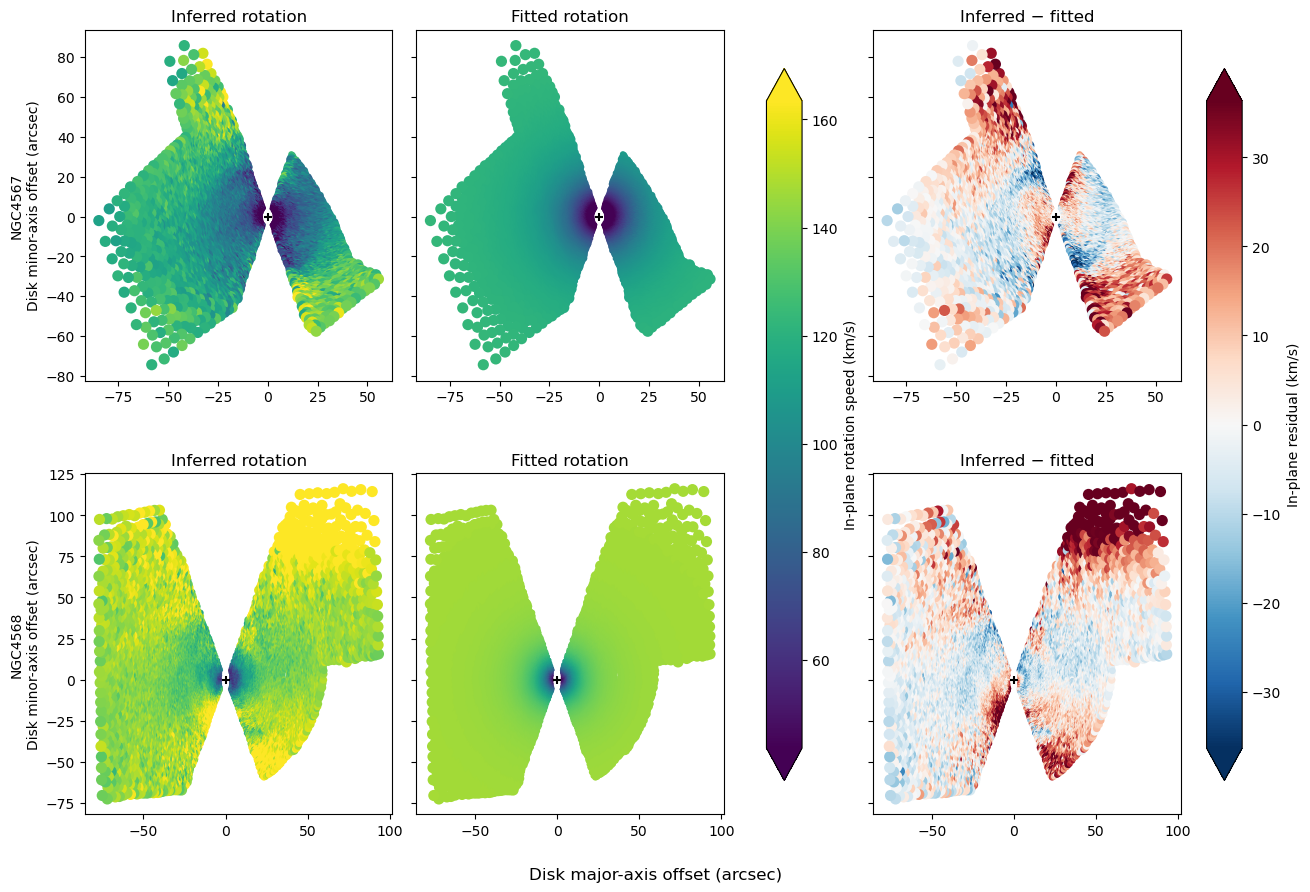

In [10]:
def plot_disk_plane(velocity, parameters, fit_bins, tracer, output_name):
    face_on_cos_min = 0.35
    face_on_fields = {}
    for galaxy, inc, offset, training in zip(GALAXIES, inclination, offsets, fit_bins):
        v0, amplitude, pa, turnover = parameters[galaxy]
        disk_x, disk_y, disk_radius = stellar_disk_coordinates(offset, inc, pa)
        cos_theta = np.divide(disk_x, disk_radius, out=np.zeros_like(disk_x), where=disk_radius > 0)
        projection = np.sin(np.deg2rad(inc)) * cos_theta
        show = training & (np.abs(cos_theta) >= face_on_cos_min)
        inferred = (velocity[show] - v0) / projection[show]
        model_speed = (amplitude / np.sin(np.deg2rad(inc))) * (
            disk_radius[show] / np.hypot(disk_radius[show], turnover)
        )
        face_on_fields[galaxy] = (show, disk_x[show], disk_y[show], inferred, model_speed)

    face_speed_values = np.concatenate([np.concatenate(fields[3:]) for fields in face_on_fields.values()])
    face_speed_limits = np.percentile(face_speed_values, [2, 98])
    face_residual_limit = np.percentile(np.abs(np.concatenate([
        inferred - model_speed for _, _, _, inferred, model_speed in face_on_fields.values()
    ])), 98)

    fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex="row", sharey="row")
    for row, galaxy in zip(axes, GALAXIES):
        show, disk_x, disk_y, inferred, model_speed = face_on_fields[galaxy]
        marker_area = np.clip(2 * counts[show], 4, 65)
        for ax, speed, title in zip(row[:2], [inferred, model_speed], ["Inferred rotation", "Fitted rotation"]):
            velocity_plot = ax.scatter(disk_x, disk_y, c=speed, s=marker_area, cmap="viridis",
                                       vmin=face_speed_limits[0], vmax=face_speed_limits[1],
                                       linewidths=0, rasterized=True)
            ax.set_title(title)
        residual_plot = row[2].scatter(disk_x, disk_y, c=inferred - model_speed, s=marker_area,
                                       cmap="RdBu_r", vmin=-face_residual_limit, vmax=face_residual_limit,
                                       linewidths=0, rasterized=True)
        row[2].set_title("Inferred − fitted")
        row[0].set_ylabel(f"{galaxy}\nDisk minor-axis offset (arcsec)")
        for ax in row:
            ax.scatter(0, 0, marker="+", color="black", s=35, zorder=3)
            ax.set_aspect("equal")
    fig.colorbar(velocity_plot, ax=axes[:, :2], shrink=.82, extend="both", label="In-plane rotation speed (km/s)")
    fig.colorbar(residual_plot, ax=axes[:, 2], shrink=.82, extend="both", label="In-plane residual (km/s)")
    if tracer != "stellar":
        fig.suptitle(f"{tracer} rotation in the disk plane")
    fig.supxlabel("Disk major-axis offset (arcsec)")
    show_save(fig, output_name)


plot_disk_plane(star, stellar_fit_parameters, stellar_fit_bins, "stellar", "05_stellar_velocity_disk_plane")


,Galaxy,Mixing bins with prediction,Mixing bins beyond radial support,Mixing bins with residual,Mixing bins passing velocity QC,"Mixing median |residual|, QC bins (km/s)"
0,NGC4567,2864,271,2864,2864,8.01
1,NGC4568,2864,196,2864,2864,7.55


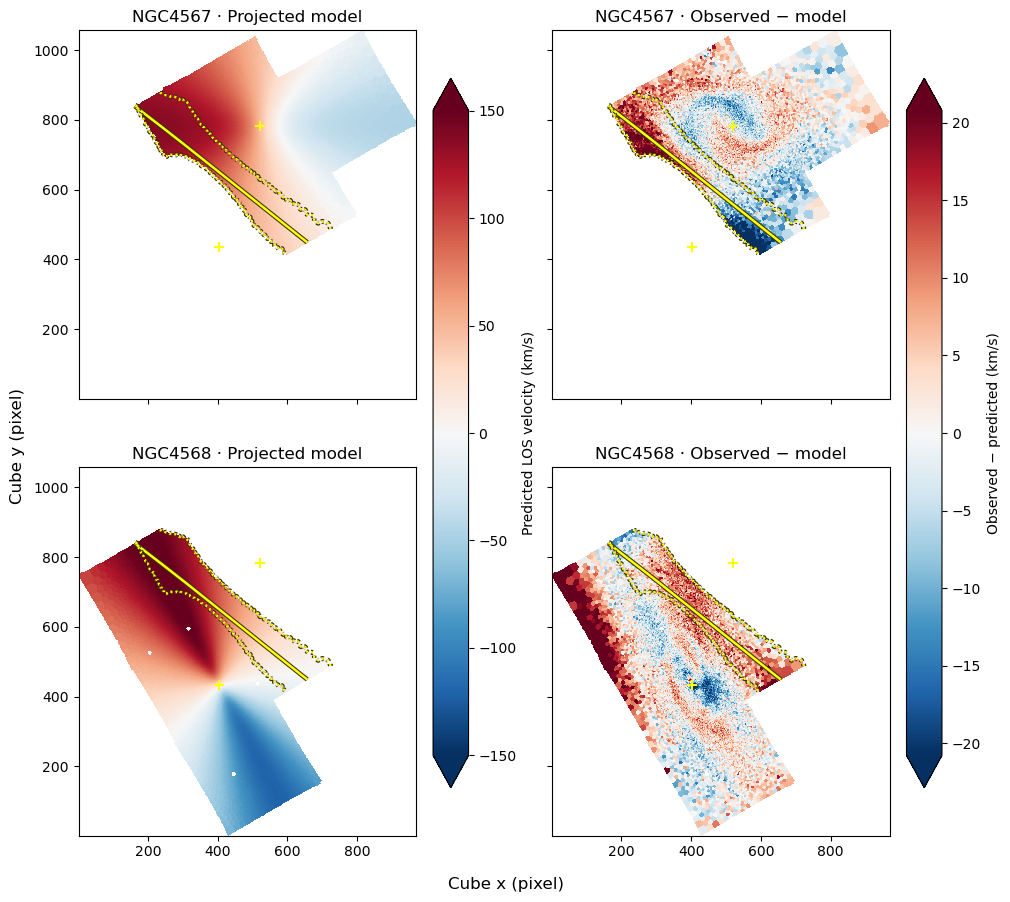

In [11]:
def stellar_bin_image(values):
    image = np.full((ny, nx), np.nan)
    image[footprint] = values[inverse]
    return image

def plot_projected_disks(velocity, quality, models, tracer, output_name):
    projected_fit_fields = {}
    projected_rows = []
    mixing_qc = bin_mixing & quality
    for galaxy, on_side in zip(GALAXIES, stellar_training_side):
        predicted, _, support = models[galaxy]
        show = on_side | bin_mixing
        prediction_map = np.where(show, predicted, np.nan)
        residual_map = np.where(show & np.isfinite(velocity), velocity - predicted, np.nan)
        projected_fit_fields[galaxy] = (prediction_map, residual_map)
        projected_rows.append({
            "Galaxy": galaxy,
            "Mixing bins with prediction": np.count_nonzero(bin_mixing & np.isfinite(prediction_map)),
            "Mixing bins beyond radial support": np.count_nonzero(bin_mixing & ~support),
            "Mixing bins with residual": np.count_nonzero(bin_mixing & np.isfinite(residual_map)),
            "Mixing bins passing velocity QC": mixing_qc.sum(),
            "Mixing median |residual|, QC bins (km/s)": np.median(np.abs(residual_map[mixing_qc])) if mixing_qc.any() else np.nan,
        })
    display(pd.DataFrame(projected_rows).round(2))

    projected_limit = np.nanpercentile(np.abs([fields[0] for fields in projected_fit_fields.values()]), 98)
    projected_residual_limit = np.nanpercentile(np.abs([fields[1] for fields in projected_fit_fields.values()]), 98)
    fig, axes = plt.subplots(2, 2, figsize=(10, 9), layout="constrained", sharex=True, sharey=True)
    for row, galaxy in zip(axes, GALAXIES):
        prediction_map, residual_map = projected_fit_fields[galaxy]
        predicted_plot = panel(row[0], stellar_bin_image(prediction_map), f"{galaxy} · Projected model",
                               cmap="RdBu_r", vmin=-projected_limit, vmax=projected_limit)
        residual_plot = panel(row[1], stellar_bin_image(residual_map), f"{galaxy} · Observed − model",
                              cmap="RdBu_r", vmin=-projected_residual_limit, vmax=projected_residual_limit)
        for ax in row:
            draw_light_boundaries(ax, stellar_bin_image(bin_mixing))
    fig.colorbar(predicted_plot, ax=axes[:, 0], shrink=.82, extend="both", label="Predicted LOS velocity (km/s)")
    fig.colorbar(residual_plot, ax=axes[:, 1], shrink=.82, extend="both", label="Observed − predicted (km/s)")
    if tracer != "stellar":
        fig.suptitle(f"Projected {tracer} velocities and residuals")
    fig.supxlabel("Cube x (pixel)")
    fig.supylabel("Cube y (pixel)")
    show_save(fig, output_name)
    return projected_fit_fields


projected_fit_fields = plot_projected_disks(star, stellar_qc, stellar_models, "stellar", "06_stellar_velocity_projected_mixing")


## 5. Update the photometric assignment using stellar velocity

Compare the two models at the Voronoi-bin scale, where each stellar velocity is measured. Sum each Sérsic component over the pixels in a bin to obtain $F_{4567}$ and $F_{4568}$. The light-only score is $D_{\rm light}=\ln(F_{4567}/F_{4568})$. This is the binned version of the continuous light comparison in cell 11. The baseline assignment gives precedence to a confident region touched by the bin. If a bin touches both masks, it keeps the light-based bin label and the confident spaxels retain their own galaxy labels in the map.

For each galaxy $g$, subtract its predicted velocity from the same observed bin velocity. The signed residual $r_g=v_\star-v_{\star,g}$ tells us by how many km/s the model underpredicts (positive) or overpredicts (negative) the measured velocity. Divide by $u_g=\sqrt{\epsilon_\star^2+s_g^2}$ before comparing the residuals. Here $\epsilon_\star$ is the bin's measurement error and $s_g$ is the RMS residual of the final disk fit on its own unmixed training bins. The same $\epsilon_\star$ enters both comparisons, while $s_g$ can differ between the galaxies. Because the fit residuals already include measurement noise, $u_g$ is a practical scaling for the score. The resulting penalty is

$$
\chi^2_g=\frac{(v_\star-v_{\star,g})^2}{\epsilon_\star^2+s_g^2}.
$$

Consider velocity updates only for bins in the configured modeled-light band that touch neither confident region. These bins lie outside the two velocity training sets. Use the two projected predictions from cell 17 across the entire band, including extrapolations beyond the fitted radial support. A bin receives a velocity term if its stellar measurement passes the quality cut and at least one model predicts it within four effective standard deviations. All other bins keep their baseline assignment. The summary counts extrapolated cases separately.

For eligible bins, use $D_{\rm light+\star}=D_{\rm light}+(\chi^2_{4568}-\chi^2_{4567})/2$. This adds positive evidence for NGC4567 when its standardized squared residual is smaller. A positive total favors NGC4567 and a negative total favors NGC4568. A combined-score tie uses the light-only label, and a light-only tie goes to NGC4567. The score combines modeled light and velocity agreement with unit weight for the velocity term. This is a heuristic assignment score. A calibrated Gaussian likelihood ratio would also include the variance normalization when the two effective errors differ. One measured centroid can represent blended stellar light, so the result is a candidate segmentation rather than a measurement of two velocities in the same bin.

Compare the two assignments on the same bin grid. The solid yellow line marks the continuous equal-light boundary, and the dotted yellow lines mark the edges of the mixing band. The change map distinguishes bins where velocity entered the score from the subset that switched galaxy.

The final two-panel figure shows the binary assignment and overlays its boundary on the observed R-band image. The solid purple line traces shared pixel edges where the final galaxy label changes.


,Selection,Bins,Spaxels
0,20–80% light bins protected by a confident mask,1913,53058
1,Mixing bins outside confident masks,2864,66001
2,Stellar velocity used,2864,66001
3,Velocity used beyond at least one model's radi...,391,22448
4,Switched beyond at least one model's radial su...,37,2200
5,Switched to NGC4567,106,2856
6,Switched to NGC4568,358,10053


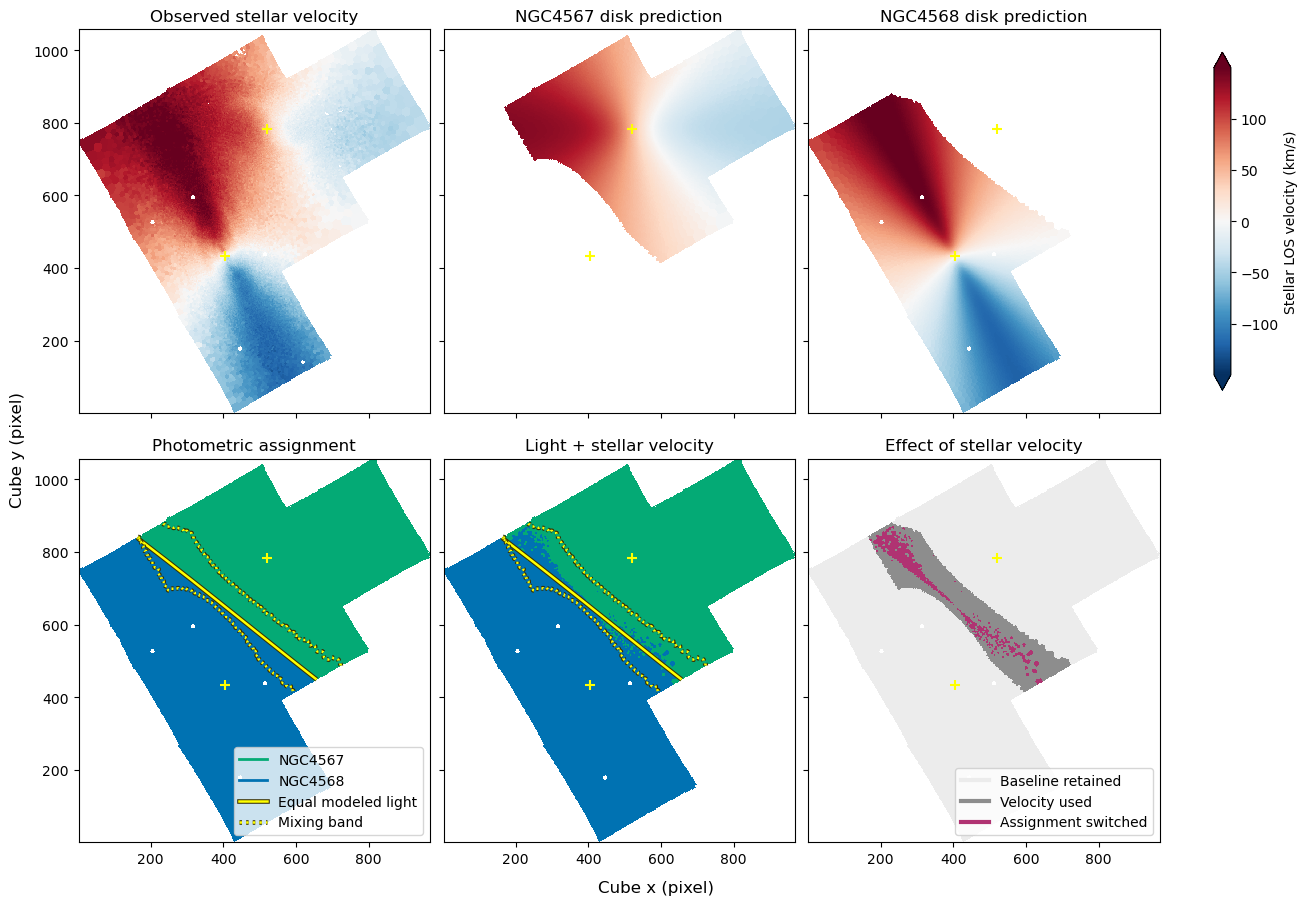

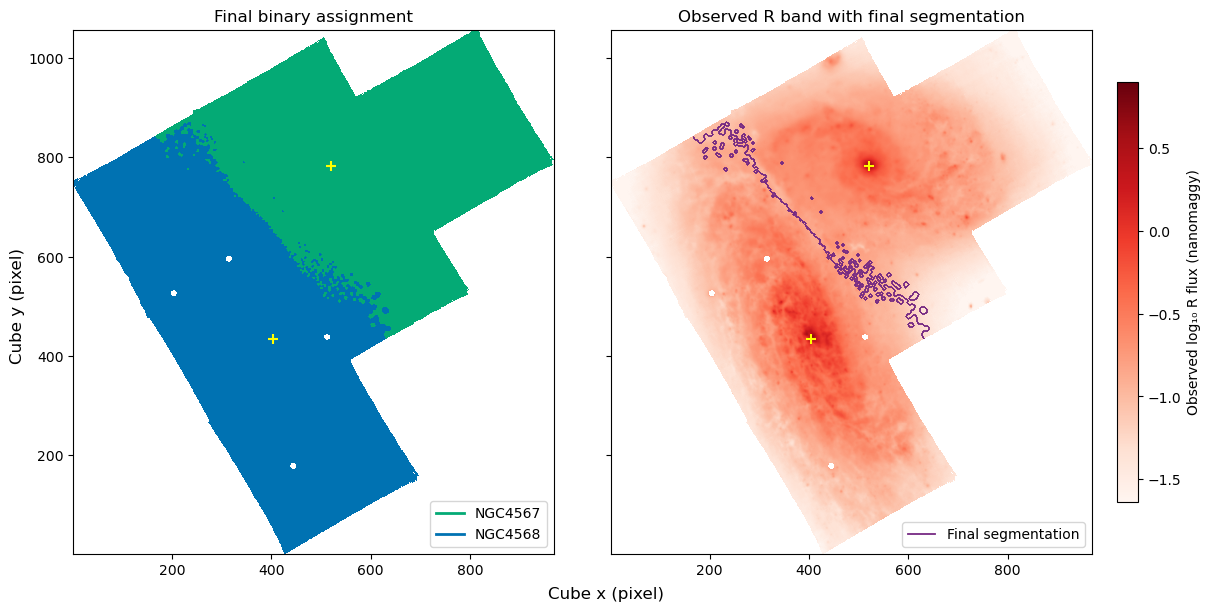

In [12]:
from matplotlib.collections import LineCollection

light_bin_score = np.log(component_bin_flux[0] / component_bin_flux[1])
light_bin_label = np.where(confident_bin_lock[0], 1, np.where(
    confident_bin_lock[1], 2, np.where(light_bin_score >= 0, 1, 2)
))
galaxy_cmap = ListedColormap([geometry_colours[g] for g in GALAXIES])


def score_velocity_assignment(error, quality, models, projected_fields):
    _, scatter, support = map(np.asarray, zip(*models.values()))
    effective_error = np.hypot(scatter[:, None], np.where(quality, error, np.nan))
    residual = np.array([projected_fields[g][1] for g in GALAXIES])
    penalty = (residual / effective_error)**2
    use = bin_mixing & quality & (penalty.min(axis=0) <= 16)
    mixing_extrapolated = bin_mixing & ~support.all(axis=0)
    term = np.where(use, 0.5 * (penalty[1] - penalty[0]), 0.)
    combined_score = light_bin_score + term
    label = np.where(use & (combined_score != 0),
                                  np.where(combined_score > 0, 1, 2), light_bin_label)
    switched = light_bin_label != label
    return combined_score, label, use, switched, mixing_extrapolated


def summarize_velocity_assignment(tracer, labels, use, switched, mixing_extrapolated):
    mixing_range_label = f"{100 * mixing_limits[0]:g}–{100 * mixing_limits[1]:g}%"
    assignment_summary = pd.DataFrame([
        {"Selection": name, "Bins": mask.sum(), "Spaxels": counts[mask].sum()}
        for name, mask in [
            (f"{mixing_range_label} light bins protected by a confident mask", fraction_in_band & ~no_confident_pixels),
            ("Mixing bins outside confident masks", bin_mixing),
            (f"{tracer.capitalize()} velocity used", use),
            ("Velocity used beyond at least one model's radial support", use & mixing_extrapolated),
            ("Switched beyond at least one model's radial support", switched & mixing_extrapolated),
            ("Switched to NGC4567", switched & (labels == 1)),
            ("Switched to NGC4568", switched & (labels == 2)),
        ]
    ])
    return assignment_summary


def plot_velocity_assignment(velocity, quality, projected_fields, labels, use, switched, tracer, output_name):
    fig, axes = plt.subplots(2, 3, figsize=(13, 9), layout="constrained", sharex=True, sharey=True)
    velocity_fields = [np.where(quality, velocity, np.nan), *[projected_fields[g][0] for g in GALAXIES]]
    velocity_limit = np.nanpercentile(np.abs(velocity_fields), 98)
    for ax, values, title in zip(axes[0], velocity_fields,
                                 [f"Observed {tracer} velocity", "NGC4567 disk prediction", "NGC4568 disk prediction"]):
        im = panel(ax, stellar_bin_image(values), title, cmap="RdBu_r",
                   vmin=-velocity_limit, vmax=velocity_limit)
    fig.colorbar(im, ax=axes[0], shrink=.85, extend="both", label=f"{tracer.capitalize()} LOS velocity (km/s)")

    photometric_assignment = stellar_bin_image(light_bin_label)
    final_assignment = stellar_bin_image(labels)
    for galaxy_id, galaxy in enumerate(GALAXIES, start=1):
        photometric_assignment[confident_regions[galaxy]] = galaxy_id
        final_assignment[confident_regions[galaxy]] = galaxy_id
    for ax, assignment, title in zip(axes[1, :2], [photometric_assignment, final_assignment],
                                     ["Photometric assignment", f"Light + {tracer} velocity"]):
        panel(ax, assignment, title, cmap=galaxy_cmap, norm=label_norm)
        draw_light_boundaries(ax, stellar_bin_image(bin_mixing))
    axes[1, 0].legend(handles=galaxy_handles + [
        Line2D([], [], label="Equal modeled light", **equal_light_style),
        Line2D([], [], ls=":", label="Mixing band", **equal_light_style),
    ], loc="lower right")
    change_cmap = ListedColormap(["#ececec", "#8d8d8d", "#b03372"])
    change = np.where(switched, 2, np.where(use, 1, 0))
    panel(axes[1, 2], stellar_bin_image(change), f"Effect of {tracer} velocity",
          cmap=change_cmap, norm=BoundaryNorm([-.5, .5, 1.5, 2.5], change_cmap.N))
    axes[1, 2].legend(handles=[
        Line2D([], [], lw=3, color=change_cmap(0), label="Baseline retained"),
        Line2D([], [], lw=3, color=change_cmap(1), label="Velocity used"),
        Line2D([], [], lw=3, color=change_cmap(2), label="Assignment switched"),
    ], loc="lower right")
    fig.supxlabel("Cube x (pixel)")
    fig.supylabel("Cube y (pixel)")
    show_save(fig, output_name)
    return final_assignment


def plot_final_segmentation(final_assignment, title, output_name):
    # Trace shared pixel edges where the final galaxy label changes.
    vertical_y, vertical_x = np.nonzero(np.abs(np.diff(final_assignment, axis=1)) == 1)
    horizontal_y, horizontal_x = np.nonzero(np.abs(np.diff(final_assignment, axis=0)) == 1)
    vertical_edges = np.stack([
        np.column_stack([vertical_x + 0.5, vertical_y - 0.5]),
        np.column_stack([vertical_x + 0.5, vertical_y + 0.5]),
    ], axis=1)
    horizontal_edges = np.stack([
        np.column_stack([horizontal_x - 0.5, horizontal_y + 0.5]),
        np.column_stack([horizontal_x + 0.5, horizontal_y + 0.5]),
    ], axis=1)
    segmentation_edges = np.concatenate([vertical_edges, horizontal_edges])

    fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained", sharex=True, sharey=True)
    panel(axes[0], final_assignment, title, cmap=galaxy_cmap, norm=label_norm)
    axes[0].legend(handles=galaxy_handles, loc="lower right")
    im = panel(axes[1], observed_light, "Observed R band with final segmentation",
               cmap="Reds", **light_limits)
    boundary_colour = "#762a83"
    axes[1].add_collection(LineCollection(
        segmentation_edges, colors=boundary_colour, linewidths=1.3, linestyles="solid", zorder=3,
    ))
    axes[1].legend(handles=[Line2D([], [], color=boundary_colour, lw=1.3, label="Final segmentation")],
                   loc="lower right")
    fig.colorbar(im, ax=axes[1], shrink=.8, label="Observed log₁₀ R flux (nanomaggy)")
    fig.supxlabel("Cube x (pixel)")
    fig.supylabel("Cube y (pixel)")
    show_save(fig, output_name)
    return segmentation_edges


light_stellar_score, light_stellar_label, stellar_use, stellar_switch, mixing_extrapolated = score_velocity_assignment(
    star_err, stellar_qc, stellar_models, projected_fit_fields,
)
stellar_assignment_summary = summarize_velocity_assignment(
    "stellar", light_stellar_label, stellar_use, stellar_switch, mixing_extrapolated,
)
display(stellar_assignment_summary)
final_assignment = plot_velocity_assignment(
    star, stellar_qc, projected_fit_fields, light_stellar_label, stellar_use, stellar_switch,
    "stellar", "07_stellar_velocity_boundary",
)
segmentation_edges = plot_final_segmentation(final_assignment, "Final binary assignment", "08_final_stellar_segmentation")


## 6. Repeat the segmentation with Hα velocities

Use one Hα line-of-sight velocity per Voronoi bin from the nGIST gas map. Use HA6562_VEL for the velocity, HA6562_VEL_ERR for its formal error, and HA6562_FLUX divided by HA6562_FLUX_ERR for the line S/N. Train each Hα disk on its own eligible unmixed bins with finite velocity and **S/N > 3**. Apply the same centre exclusion as for the stellar fits. There is no upper cut on the Hα velocity error. A finite, nonnegative formal error is needed to standardize a residual in the assignment.

Keep the Sérsic light model, confident masks, and mixing band fixed. Fit an Hα rotation model for each galaxy with the same fixed centre and inclination used for the stellar fit. Fit the velocity zero point, projected rotation amplitude, receding PA, and turnover radius to the observed velocities. The error scale for each galaxy is the RMS of the final Hα fit residuals in its own unmixed training bins. The maps show the inferred and fitted in-plane speeds, the projected models over each galaxy's side plus the entire mixing band, and the observed-minus-predicted residuals where Hα passes the S/N cut.

Start from the **photometric assignment** and add the Hα velocity term in the mixing bins. Compare the measured Hα centroid with both disk predictions, using the formal Hα velocity error and each disk's RMS to scale its residual. Use the same four-effective-standard-deviation check and retain the photometric assignment wherever the velocity term is unavailable. The comparison table counts where Hα and stellar velocity give different labels, including on the subset where both tracers entered the score. The solid purple line traces the Hα-based final binary assignment.


In [13]:
ha_velocity, ha_velocity_error, ha_snr_ok = tracers["Hα"]
ha_quality = np.isfinite(ha_velocity) & ha_snr_ok
ha_score_quality = ha_quality & np.isfinite(ha_velocity_error) & (ha_velocity_error >= 0)
ha_models, ha_fit_parameters, ha_fit_bins, ha_fit_summary = fit_disk_models(ha_velocity, ha_quality)
display(ha_fit_summary.round(2))


,Galaxy,Fit bins,v0 (km/s),A (km/s),Kinematic PA (deg),V_inf (km/s),Rt (arcsec),Fit RMS residual (km/s),Fit P90 absolute residual (km/s),Support radius (arcsec),Parameters at bounds
0,NGC4567,9710,45.83,85.04,90.49,112.67,8.44,10.12,15.53,74.42,0
1,NGC4568,18078,14.43,145.44,28.08,154.78,7.90,10.07,16.57,108.91,0


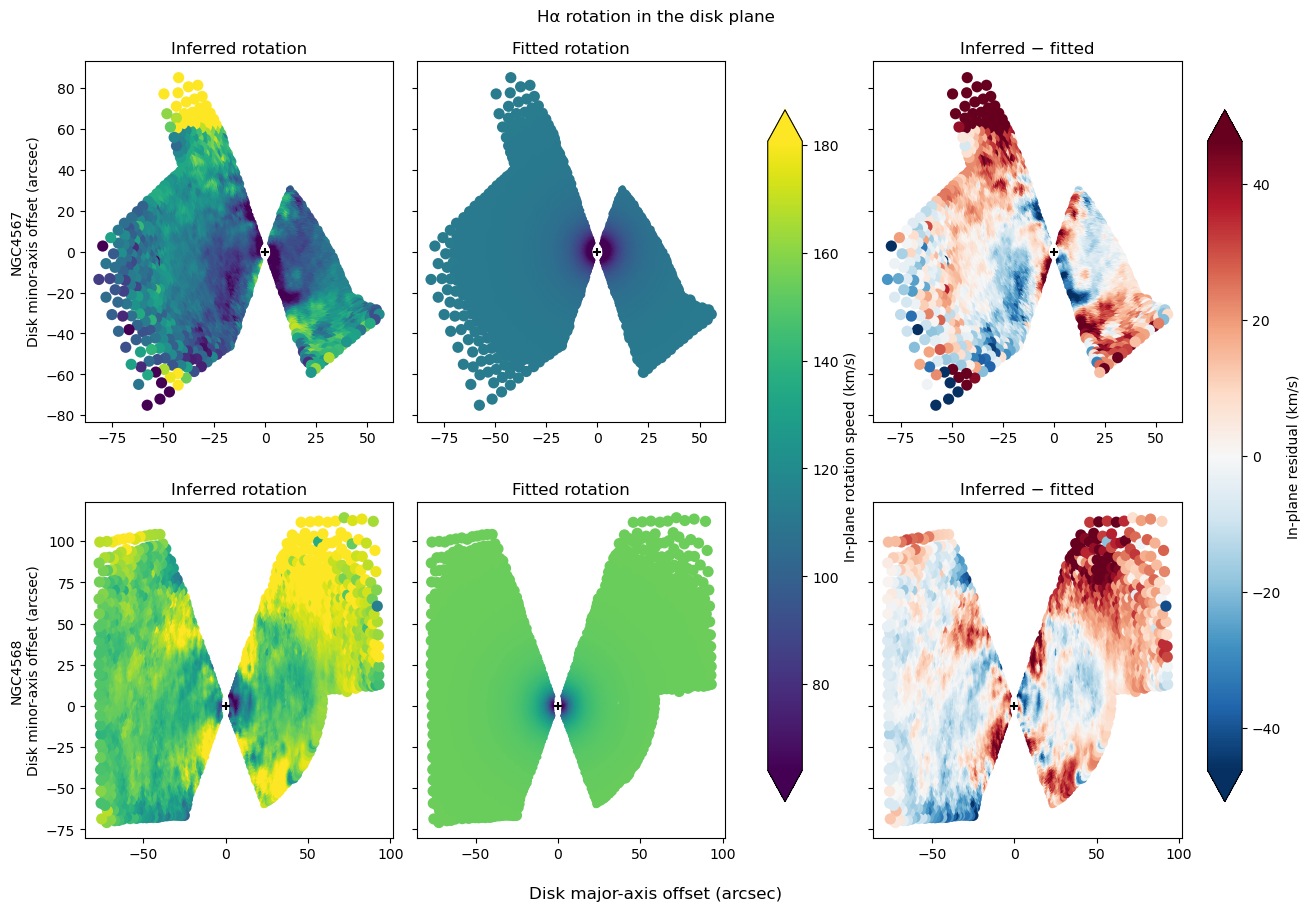

,Galaxy,Mixing bins with prediction,Mixing bins beyond radial support,Mixing bins with residual,Mixing bins passing velocity QC,"Mixing median |residual|, QC bins (km/s)"
0,NGC4567,2864,276,2864,2864,11.50
1,NGC4568,2864,204,2864,2864,11.33


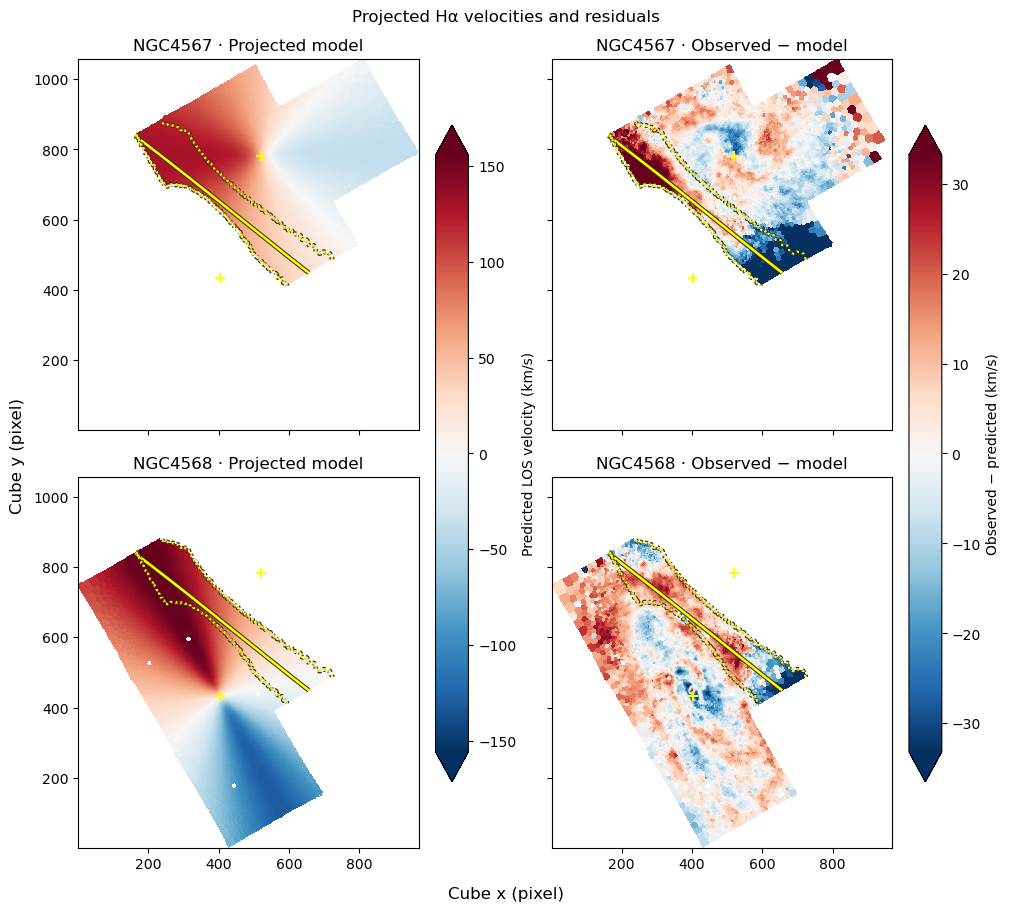

In [14]:
plot_disk_plane(ha_velocity, ha_fit_parameters, ha_fit_bins, "Hα", "09_halpha_velocity_disk_plane")
ha_projected_fields = plot_projected_disks(
    np.where(ha_quality, ha_velocity, np.nan), ha_quality, ha_models, "Hα", "10_halpha_velocity_projected_mixing",
)


,Selection,Bins,Spaxels
0,20–80% light bins protected by a confident mask,1913,53058
1,Mixing bins outside confident masks,2864,66001
2,Hα velocity used,2864,66001
3,Velocity used beyond at least one model's radi...,401,22707
4,Switched beyond at least one model's radial su...,137,11588
5,Switched to NGC4567,188,4417
6,Switched to NGC4568,513,20631


,Selection,Bins,Different Hα and stellar labels (bins),Different Hα and stellar labels (spaxels)
0,All mixing bins,2864,415,17299
1,Both velocity terms used,2864,415,17299


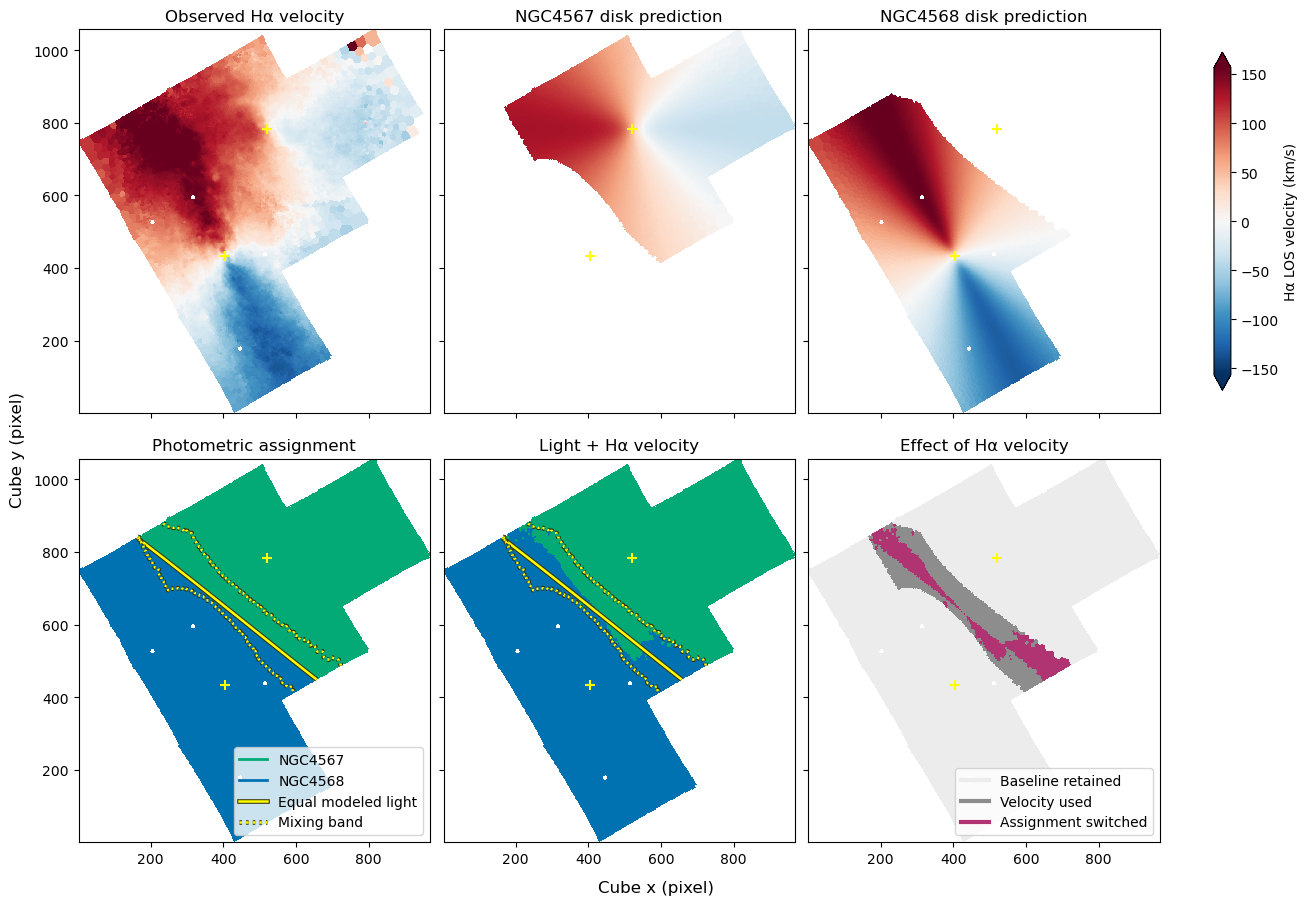

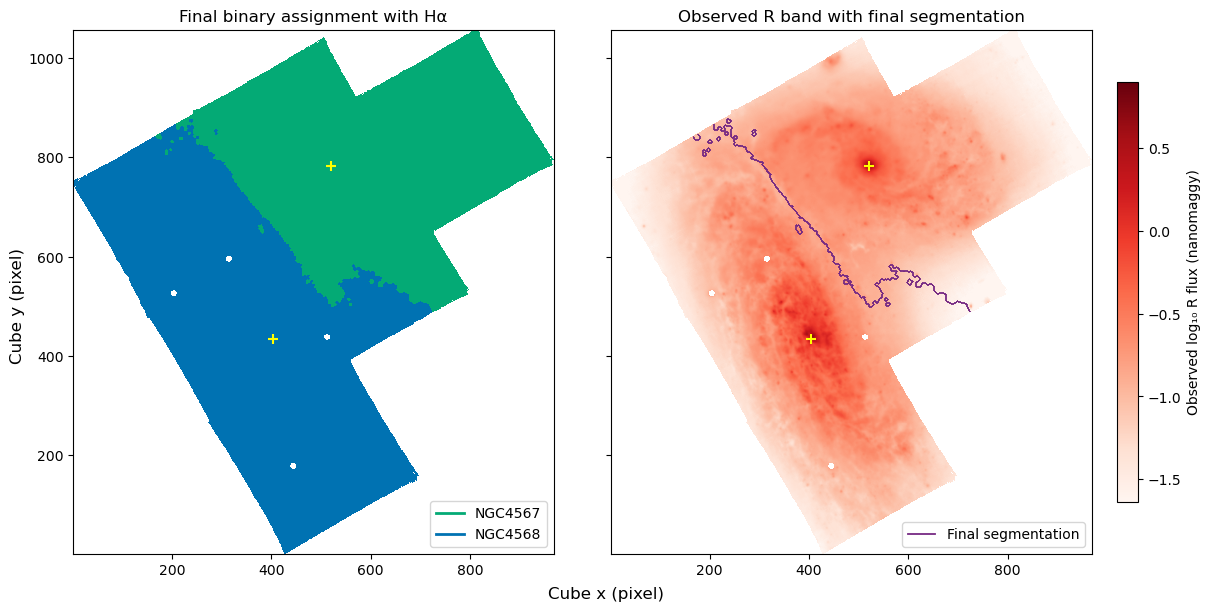

In [15]:
light_ha_score, light_ha_label, ha_use, ha_switch, ha_extrapolated = score_velocity_assignment(
    ha_velocity_error, ha_score_quality, ha_models, ha_projected_fields,
)
ha_assignment_summary = summarize_velocity_assignment("Hα", light_ha_label, ha_use, ha_switch, ha_extrapolated)
display(ha_assignment_summary)

tracer_disagreement = light_ha_label != light_stellar_label
tracer_comparison = pd.DataFrame([
    {"Selection": name, "Bins": mask.sum(),
     "Different Hα and stellar labels (bins)": (mask & tracer_disagreement).sum(),
     "Different Hα and stellar labels (spaxels)": counts[mask & tracer_disagreement].sum()}
    for name, mask in [("All mixing bins", bin_mixing), ("Both velocity terms used", ha_use & stellar_use)]
])
display(tracer_comparison)

ha_final_assignment = plot_velocity_assignment(
    ha_velocity, ha_quality, ha_projected_fields, light_ha_label, ha_use, ha_switch,
    "Hα", "11_halpha_velocity_boundary",
)
ha_segmentation_edges = plot_final_segmentation(
    ha_final_assignment, "Final binary assignment with Hα", "12_final_halpha_segmentation",
)
